Project Overview

In [ ]:
# Customer Experience Analytics Project
# Author: Sahil S Kumar
#
# Objective:
# Analyse customer survey responses to identify
# NPS trends, customer satisfaction patterns,
# and opportunities to improve customer experience.
#
# Dataset:
# 5,000 synthetic customer survey records.
# All records are fictional and created for learning.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

print("Libraries imported successfully!")

Libraries imported successfully!


1. Setup and Dataset Creation

In [ ]:
n = 5000

df = pd.DataFrame({
    "Customer_ID": [f"CUST{i:05d}" for i in range(10001, 10001 + n)],
    "Survey_Date": pd.to_datetime(
        np.random.choice(
            pd.date_range("2026-01-01", "2026-09-30"),
            n
        )
    ),
    "Region": np.random.choice(
        ["India", "UK", "USA", "Europe"],
        n
    ),
    "Contact_Reason": np.random.choice(
        ["Booking", "Refund", "Payment", "Communication", "Cancellation", "Account"],
        n
    ),
    "Service_Group": np.random.choice(
        ["Reservations", "Payments", "Customer Support", "Trust and Safety"],
        n
    ),
    "Customer_Type": np.random.choice(
        ["Guest", "Host"],
        n
    ),
    "NPS_Rating": np.random.randint(0, 11, n),
    "CSAT": np.random.randint(1, 6, n),
    "CES": np.random.randint(1, 6, n),
    "Resolution_Status": np.random.choice(
        ["Resolved", "Pending", "Escalated"],
        n,
        p=[0.75, 0.15, 0.10]
    )
})

df.head()

,Customer_ID,Survey_Date,Region,Contact_Reason,Service_Group,Customer_Type,NPS_Rating,CSAT,CES,Resolution_Status
0,CUST10001,2026-05-21,USA,Account,Reservations,Guest,3,1,4,Escalated
1,CUST10002,2026-06-01,USA,Cancellation,Trust and Safety,Guest,8,4,1,Resolved
2,CUST10003,2026-04-24,USA,Account,Trust and Safety,Host,10,3,4,Resolved
3,CUST10004,2026-02-19,Europe,Refund,Reservations,Guest,8,3,5,Resolved
4,CUST10005,2026-07-19,USA,Refund,Trust and Safety,Host,7,4,1,Resolved


2. Data Quality Checks

In [ ]:
# Check the number of rows and columns
print("Dataset size:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check the data types and missing values
print("\nDataset information:")
df.info()

Dataset size: (5000, 10)

Column names:
['Customer_ID', 'Survey_Date', 'Region', 'Contact_Reason', 'Service_Group', 'Customer_Type', 'NPS_Rating', 'CSAT', 'CES', 'Resolution_Status']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Customer_ID        5000 non-null   object        
 1   Survey_Date        5000 non-null   datetime64[ns]
 2   Region             5000 non-null   object        
 3   Contact_Reason     5000 non-null   object        
 4   Service_Group      5000 non-null   object        
 5   Customer_Type      5000 non-null   object        
 6   NPS_Rating         5000 non-null   int64         
 7   CSAT               5000 non-null   int64         
 8   CES                5000 non-null   int64         
 9   Resolution_Status  5000 non-null   object        
dtypes: datetime64[ns](1), i

In [ ]:
# 1. Check for missing values
print("Missing values in each columns:")
print(df.isnull().sum())

# 2. Check for duplicate records
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# 3. Check for the duplicate customer IDs
print("\nDuplicate customer IDs:")
print(df["Customer_ID"].duplicated().sum())

Missing values in each columns:
Customer_ID          0
Survey_Date          0
Region               0
Contact_Reason       0
Service_Group        0
Customer_Type        0
NPS_Rating           0
CSAT                 0
CES                  0
Resolution_Status    0
dtype: int64

Number of duplicate rows:
0

Duplicate customer IDs:
0


3. NPS Segmentation and Overall NPS

In [ ]:
# Classify customers based on their NPS rating
def classify_nps(rating):
  if rating >= 9:
    return "Promoters"
  elif rating >= 7:
    return "Passives"
  else:
    return "Detractors"
# Create a new column containing the segment
df["NPS_Segment"] = df["NPS_Rating"].apply(classify_nps)

# Display the first five records
df.head()

,Customer_ID,Survey_Date,Region,Contact_Reason,Service_Group,Customer_Type,NPS_Rating,CSAT,CES,Resolution_Status,NPS_Segment
0,CUST10001,2026-05-21,USA,Account,Reservations,Guest,3,1,4,Escalated,Detractors
1,CUST10002,2026-06-01,USA,Cancellation,Trust and Safety,Guest,8,4,1,Resolved,Passives
2,CUST10003,2026-04-24,USA,Account,Trust and Safety,Host,10,3,4,Resolved,Promoters
3,CUST10004,2026-02-19,Europe,Refund,Reservations,Guest,8,3,5,Resolved,Passives
4,CUST10005,2026-07-19,USA,Refund,Trust and Safety,Host,7,4,1,Resolved,Passives


In [ ]:
# Count customers in each NPS segment
segment_counts = df["NPS_Segment"].value_counts()

print("Customer Segment Counts:")
print(segment_counts)

# Calculate customer segment percentages
promoters_pct = (segment_counts.get("Promoters", 0) / len(df)) * 100
passives_pct = (segment_counts.get("Passives", 0) / len(df)) * 100
detractors_pct = (segment_counts.get("Detractors", 0) / len(df)) * 100

# Calculate overall NPS
nps = promoters_pct - detractors_pct

print("\nCustomer Segment Percentages:")
print(f"Promoters: {promoters_pct:.2f}%")
print(f"Passives: {passives_pct:.2f}%")
print(f"Detractors: {detractors_pct:.2f}%")

print(f'\nOverall NPS: {nps:.2f}')

Customer Segment Counts:
NPS_Segment
Detractors    3109
Promoters      952
Passives       939
Name: count, dtype: int64

Customer Segment Percentages:
Promoters: 19.04%
Passives: 18.78%
Detractors: 62.18%

Overall NPS: -43.14


4. NPS Analysis by Contact Reason

In [ ]:
# Calculate the average NPS rating for each contact reason
reason_analysis = df.groupby("Contact_Reason").agg(
    Average_Rating=("NPS_Rating", "mean"),
    Total_Responses=("Customer_ID", "count")
).round(2)

# Display the results, highest average rating first
reason_analysis = reason_analysis.sort_values(
    by="Average_Rating",
    ascending=False
)

reason_analysis

,Average_Rating,Total_Responses
Contact_Reason,,
Booking,5.16,812
Cancellation,5.15,839
Refund,5.09,838
Communication,5.00,821
Payment,4.99,817
Account,4.97,873


In [ ]:
# Check the actual values in the NPS_Segment column
print(df["NPS_Segment"].value_counts())

# Check a few ratings and their assigned segments
print(df[["NPS_Rating", "NPS_Segment"]].head(10))

NPS_Segment
Detractors    3109
Promoters      952
Passives       939
Name: count, dtype: int64
   NPS_Rating NPS_Segment
0           3  Detractors
1           8    Passives
2          10   Promoters
3           8    Passives
4           7    Passives
5           8    Passives
6          10   Promoters
7           0  Detractors
8           2  Detractors
9           2  Detractors


In [ ]:
reason_nps = df.groupby("Contact_Reason").apply(
    lambda group: pd.Series({
        "Total_Responses": len(group),
        "Promoters_Pct": (group["NPS_Segment"] == "Promoters").mean() * 100,
        "Detractors_Pct": (group["NPS_Segment"] == "Detractors").mean() * 100,
        "NPS": (
            (group["NPS_Segment"] == "Promoters").mean()
            - (group["NPS_Segment"] == "Detractors").mean()
        ) * 100
    })
).round(2)

reason_nps = reason_nps.sort_values("NPS")

reason_nps

/tmp/ipykernel_552/2052978369.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  reason_nps = df.groupby("Contact_Reason").apply(


,Total_Responses,Promoters_Pct,Detractors_Pct,NPS
Contact_Reason,,,,
Account,873.0,16.84,64.26,-47.42
Payment,817.0,17.75,63.28,-45.53
Communication,821.0,17.90,63.22,-45.31
Booking,812.0,21.31,62.81,-41.50
Cancellation,839.0,20.50,60.43,-39.93
Refund,838.0,20.05,59.07,-39.02


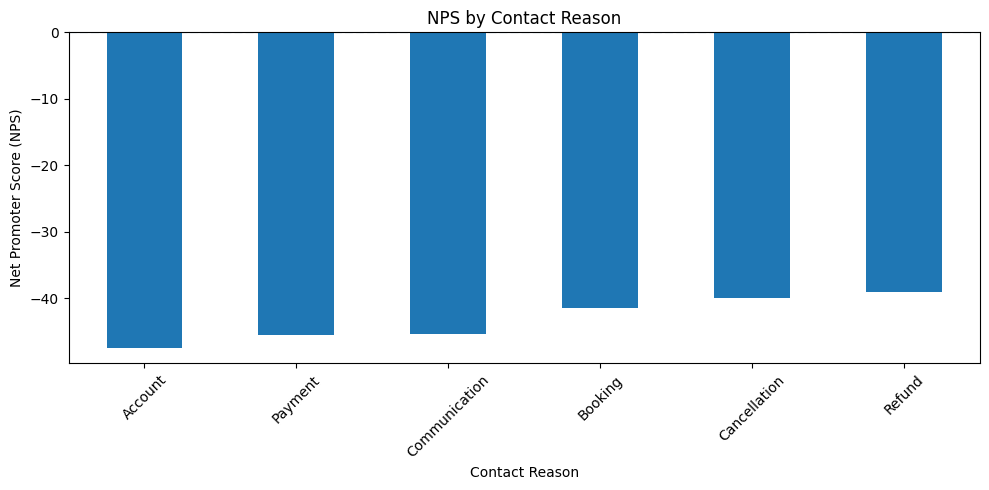

In [ ]:
import matplotlib.pyplot as plt

# Create a bar chart
reason_nps["NPS"].plot(kind="bar", figsize=(10, 5))

# Add chart title and labels
plt.title("NPS by Contact Reason")
plt.xlabel("Contact Reason")
plt.ylabel("Net Promoter Score (NPS)")
plt.axhline(y=0, linestyle="--")

# Improve layout and display
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

5. CSAT Analysis

In [ ]:
# Calculate average CSAT for each contact reason
csat_analysis = df.groupby("Contact_Reason").agg(
    Average_CSAT=("CSAT", "mean"),
    Total_Responses=("Customer_ID", "count")
).round(2)

# Sort from lowest satisfaction to highest
csat_analysis = csat_analysis.sort_values(
    by="Average_CSAT",
    ascending=True
)

csat_analysis

,Average_CSAT,Total_Responses
Contact_Reason,,
Booking,2.95,812
Refund,2.97,838
Payment,2.98,817
Cancellation,3.00,839
Account,3.03,873
Communication,3.05,821


In [ ]:
# Combine NPS and CSAT into one summary table
combined_analysis = reason_nps[
    ["Total_Responses", "NPS"]
].join(
    csat_analysis[["Average_CSAT"]],
    how="inner"
)

# Sort by NPS, lowest first
combined_analysis = combined_analysis.sort_values(
    by="NPS",
    ascending=True
)

combined_analysis.round(2)

,Total_Responses,NPS,Average_CSAT
Contact_Reason,,,
Account,873.0,-47.42,3.03
Payment,817.0,-45.53,2.98
Communication,821.0,-45.31,3.05
Booking,812.0,-41.50,2.95
Cancellation,839.0,-39.93,3.00
Refund,838.0,-39.02,2.97


6. Resolution Status Analysis

In [ ]:
# Analyse customer ratings by resolution status
resolution_analysis = df.groupby("Resolution_Status").agg(
    Total_Responses=("Customer_ID", "count"),
    Average_NPS_Rating=("NPS_Rating", "mean"),
    Average_CSAT=("CSAT", "mean"),
    Promoters_Pct=(
        "NPS_Segment",
        lambda x: (x == "Promoters").mean() * 100
    ),
    Detractors_Pct=(
        "NPS_Segment",
        lambda x: (x == "Detractors").mean() * 100
    )
).round(2)

# Calculate NPS for each resolution status
resolution_analysis["NPS"] = (
    resolution_analysis["Promoters_Pct"]
    - resolution_analysis["Detractors_Pct"]
).round(2)

resolution_analysis.sort_values("NPS")

,Total_Responses,Average_NPS_Rating,Average_CSAT,Promoters_Pct,Detractors_Pct,NPS
Resolution_Status,,,,,,
Pending,701,5.09,2.95,18.54,62.05,-43.51
Resolved,3769,5.05,3.00,19.16,62.32,-43.16
Escalated,530,5.12,3.02,18.87,61.32,-42.45


7. Customer Experience KPI Summary

In [ ]:
# Calculate overall business KPIs

total_responses = len(df)

promoters_pct = (df["NPS_Segment"] == "Promoters").mean() * 100
detractors_pct = (df["NPS_Segment"] == "Detractors").mean() * 100
overall_nps = promoters_pct - detractors_pct

average_csat = df["CSAT"].mean()

resolution_rate = (
    (df["Resolution_Status"] == "Resolved").mean() * 100
)

escalation_rate = (
    (df["Resolution_Status"] == "Escalated").mean() * 100
)

# Display the KPI summary
print("CUSTOMER EXPERIENCE KPI SUMMARY")
print("-" * 35)
print(f"Total Responses: {total_responses:,}")
print(f"Overall NPS: {overall_nps:.2f}")
print(f"Average CSAT: {average_csat:.2f} / 5")
print(f"Resolution Rate: {resolution_rate:.2f}%")
print(f"Escalation Rate: {escalation_rate:.2f}%")

CUSTOMER EXPERIENCE KPI SUMMARY
-----------------------------------
Total Responses: 5,000
Overall NPS: -43.14
Average CSAT: 3.00 / 5
Resolution Rate: 75.38%
Escalation Rate: 10.60%


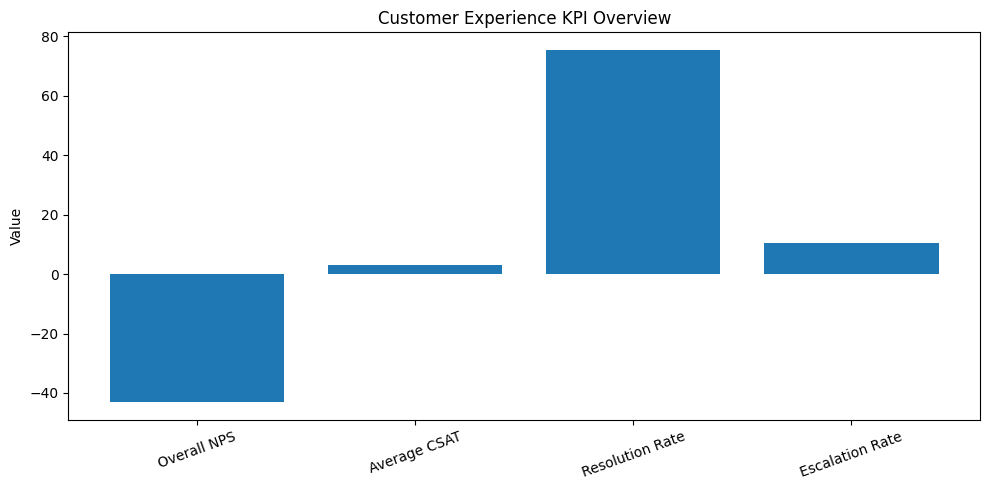

In [ ]:
import matplotlib.pyplot as plt

# Create KPI names and their values
kpi_names = [
    "Overall NPS",
    "Average CSAT",
    "Resolution Rate",
    "Escalation Rate"
]

kpi_values = [
    overall_nps,
    average_csat,
    resolution_rate,
    escalation_rate
]

# Create the chart
plt.figure(figsize=(10, 5))
plt.bar(kpi_names, kpi_values)

plt.title("Customer Experience KPI Overview")
plt.ylabel("Value")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

8. Monthly NPS Trend Analysis

In [ ]:
# Extract the month from each survey date
df["Month"] = df["Survey_Date"].dt.to_period("M")

# Calculate monthly NPS
monthly_nps = df.groupby("Month").apply(
    lambda group: (
        (group["NPS_Segment"] == "Promoters").mean()
        - (group["NPS_Segment"] == "Detractors").mean()
    ) * 100
)

# Display the results
monthly_nps = monthly_nps.round(2)

print("Monthly NPS:")
print(monthly_nps)

Monthly NPS:
Month
2026-01   -43.92
2026-02   -39.32
2026-03   -44.64
2026-04   -34.54
2026-05   -47.34
2026-06   -46.74
2026-07   -43.36
2026-08   -40.37
2026-09   -46.98
Freq: M, dtype: float64


/tmp/ipykernel_552/2036104925.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly_nps = df.groupby("Month").apply(


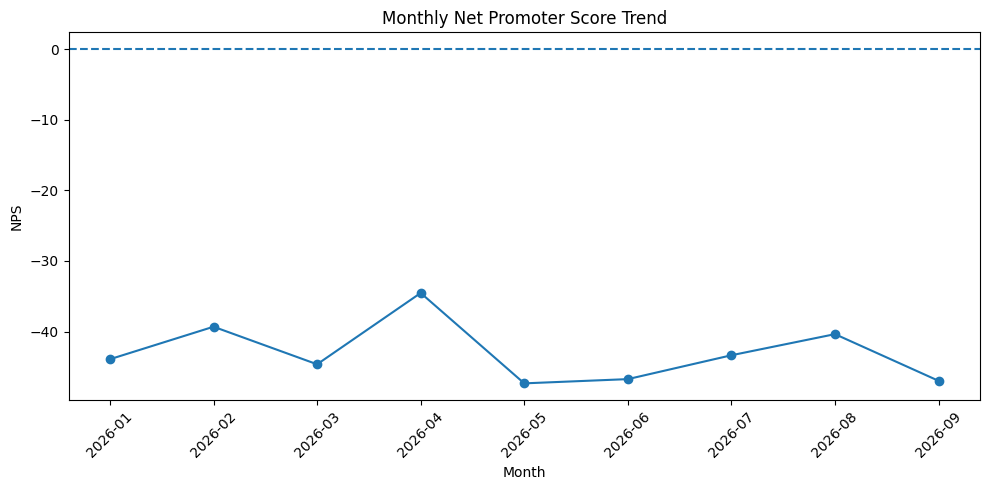

In [ ]:
import matplotlib.pyplot as plt

# Create a line chart of monthly NPS
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_nps.index.astype(str),
    monthly_nps.values,
    marker="o"
)

plt.title("Monthly Net Promoter Score Trend")
plt.xlabel("Month")
plt.ylabel("NPS")
plt.axhline(y=0, linestyle="--")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate customer satisfaction by resolution status
status_csat = df.groupby("Resolution_Status").agg(
    Total_Responses=("Customer_ID", "count"),
    Average_CSAT=("CSAT", "mean")
).round(2)

# Show the results, lowest satisfaction first
status_csat = status_csat.sort_values(
    by="Average_CSAT",
    ascending=True
)

status_csat

,Total_Responses,Average_CSAT
Resolution_Status,,
Pending,701,2.95
Resolved,3769,3.00
Escalated,530,3.02


9. Exporting the Dataset

In [ ]:
# Export the dataset to a CSV file
df.to_csv("customer_experience_data.csv", index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


10. SQL Analysis Using SQLite

In [ ]:
# Convert the Month column into text
df["Month"] = df["Month"].astype(str)

# Create a fresh SQL connection
conn = sqlite3.connect(":memory:")

# Load the dataset into SQL
df.to_sql(
    "customer_experience",
    conn,
    if_exists="replace",
    index=False
)

print("Dataset successfully loaded into SQL!")

Dataset successfully loaded into SQL!


In [ ]:
query = """
SELECT *
FROM customer_experience
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

result

,Customer_ID,Survey_Date,Region,Contact_Reason,Service_Group,Customer_Type,NPS_Rating,CSAT,CES,Resolution_Status,NPS_Segment,Month
0,CUST10001,2026-05-21 00:00:00,USA,Account,Reservations,Guest,3,1,4,Escalated,Detractors,2026-05
1,CUST10002,2026-06-01 00:00:00,USA,Cancellation,Trust and Safety,Guest,8,4,1,Resolved,Passives,2026-06
2,CUST10003,2026-04-24 00:00:00,USA,Account,Trust and Safety,Host,10,3,4,Resolved,Promoters,2026-04
3,CUST10004,2026-02-19 00:00:00,Europe,Refund,Reservations,Guest,8,3,5,Resolved,Passives,2026-02
4,CUST10005,2026-07-19 00:00:00,USA,Refund,Trust and Safety,Host,7,4,1,Resolved,Passives,2026-07
5,CUST10006,2026-07-24 00:00:00,USA,Booking,Payments,Host,8,4,3,Escalated,Passives,2026-07
6,CUST10007,2026-07-09 00:00:00,India,Refund,Customer Support,Guest,10,1,5,Resolved,Promoters,2026-07
7,CUST10008,2026-04-13 00:00:00,Europe,Booking,Customer Support,Guest,0,4,5,Resolved,Detractors,2026-04
8,CUST10009,2026-04-17 00:00:00,UK,Refund,Reservations,Guest,2,1,5,Resolved,Detractors,2026-04
9,CUST10010,2026-01-29 00:00:00,India,Refund,Payments,Guest,2,1,2,Pending,Detractors,2026-01


In [ ]:
query = """
SELECT Customer_ID, NPS_Rating, NPS_Segment, Contact_Reason
FROM customer_experience
WHERE NPS_Rating <= 6
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

result

,Customer_ID,NPS_Rating,NPS_Segment,Contact_Reason
0,CUST10001,3,Detractors,Account
1,CUST10008,0,Detractors,Booking
2,CUST10009,2,Detractors,Refund
3,CUST10010,2,Detractors,Refund
4,CUST10013,4,Detractors,Account
5,CUST10014,0,Detractors,Communication
6,CUST10015,4,Detractors,Communication
7,CUST10017,1,Detractors,Communication
8,CUST10020,1,Detractors,Payment
9,CUST10025,4,Detractors,Payment


In [ ]:
query = """
SELECT
    NPS_Segment,
    COUNT(*) AS Total_Customers
FROM customer_experience
GROUP BY NPS_Segment
ORDER BY Total_Customers DESC;
"""

result = pd.read_sql_query(query, conn)

result

,NPS_Segment,Total_Customers
0,Detractors,3109
1,Promoters,952
2,Passives,939


In [ ]:
query = """
SELECT
    Contact_Reason,
    COUNT(*) AS Total_Responses,
    SUM(CASE WHEN NPS_Segment = 'Promoters' THEN 1 ELSE 0 END) AS Promoters,
    SUM(CASE WHEN NPS_Segment = 'Detractors' THEN 1 ELSE 0 END) AS Detractors,
    ROUND(
        100.0 * SUM(CASE WHEN NPS_Segment = 'Promoters' THEN 1 ELSE 0 END) / COUNT(*)
        -
        100.0 * SUM(CASE WHEN NPS_Segment = 'Detractors' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS NPS
FROM customer_experience
GROUP BY Contact_Reason
ORDER BY NPS ASC;
"""

result = pd.read_sql_query(query, conn)

result

,Contact_Reason,Total_Responses,Promoters,Detractors,NPS
0,Account,873,147,561,-47.42
1,Payment,817,145,517,-45.53
2,Communication,821,147,519,-45.31
3,Booking,812,173,510,-41.50
4,Cancellation,839,172,507,-39.93
5,Refund,838,168,495,-39.02


In [ ]:
query = """
SELECT
    Contact_Reason,
    COUNT(*) AS Total_Responses,
    SUM(CASE WHEN NPS_Segment = 'Promoters' THEN 1 ELSE 0 END) AS Promoters,
    SUM(CASE WHEN NPS_Segment = 'Detractors' THEN 1 ELSE 0 END) AS Detractors,
    ROUND(
        100.0 * SUM(CASE WHEN NPS_Segment = 'Promoters' THEN 1 ELSE 0 END) / COUNT(*)
        -
        100.0 * SUM(CASE WHEN NPS_Segment = 'Detractors' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS NPS
FROM customer_experience
GROUP BY Contact_Reason
ORDER BY NPS ASC;
"""

result = pd.read_sql_query(query, conn)
result

,Contact_Reason,Total_Responses,Promoters,Detractors,NPS
0,Account,873,147,561,-47.42
1,Payment,817,145,517,-45.53
2,Communication,821,147,519,-45.31
3,Booking,812,173,510,-41.50
4,Cancellation,839,172,507,-39.93
5,Refund,838,168,495,-39.02


In [ ]:
query = """
SELECT
    Resolution_Status,
    COUNT(*) AS Total_Responses,
    ROUND(AVG(NPS_Rating), 2) AS Average_NPS_Rating,
    ROUND(AVG(CSAT), 2) AS Average_CSAT,
    ROUND(
        100.0 * SUM(CASE WHEN NPS_Segment = 'Promoters' THEN 1 ELSE 0 END) / COUNT(*)
        -
        100.0 * SUM(CASE WHEN NPS_Segment = 'Detractors' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS NPS
FROM customer_experience
WHERE Contact_Reason = 'Cancellation'
GROUP BY Resolution_Status
ORDER BY NPS ASC;
"""

result = pd.read_sql_query(query, conn)
result

,Resolution_Status,Total_Responses,Average_NPS_Rating,Average_CSAT,NPS
0,Escalated,97,4.89,3.16,-44.33
1,Resolved,617,5.16,2.99,-40.36
2,Pending,125,5.32,2.89,-34.40


In [ ]:
query = """
SELECT
    Contact_Reason,
    COUNT(*) AS Total_Responses,
    ROUND(AVG(CSAT), 2) AS Average_CSAT,
    ROUND(
        100.0 * SUM(CASE WHEN NPS_Segment = 'Promoters' THEN 1 ELSE 0 END) / COUNT(*)
        -
        100.0 * SUM(CASE WHEN NPS_Segment = 'Detractors' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS NPS
FROM customer_experience
WHERE Resolution_Status = 'Escalated'
GROUP BY Contact_Reason
ORDER BY NPS ASC;
"""

result = pd.read_sql_query(query, conn)
result

,Contact_Reason,Total_Responses,Average_CSAT,NPS
0,Account,85,2.98,-50.59
1,Cancellation,97,3.16,-44.33
2,Communication,89,3.17,-43.82
3,Booking,91,2.86,-42.86
4,Refund,88,3.08,-37.50
5,Payment,80,2.86,-35.00


In [ ]:
query = """
SELECT
    Resolution_Status,
    COUNT(*) AS Total_Responses,
    ROUND(AVG(CSAT), 2) AS Average_CSAT,
    ROUND(
        100.0 * SUM(CASE WHEN NPS_Segment = 'Promoters' THEN 1 ELSE 0 END) / COUNT(*)
        -
        100.0 * SUM(CASE WHEN NPS_Segment = 'Detractors' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS NPS
FROM customer_experience
GROUP BY Resolution_Status
ORDER BY NPS DESC;
"""

result = pd.read_sql_query(query, conn)
result

,Resolution_Status,Total_Responses,Average_CSAT,NPS
0,Escalated,530,3.02,-42.45
1,Resolved,3769,3.00,-43.17
2,Pending,701,2.95,-43.51


In [ ]:
query = """
SELECT
    Region,
    COUNT(*) AS Total_Responses,
    ROUND(AVG(CSAT), 2) AS Average_CSAT,
    ROUND(
        100.0 * SUM(
            CASE WHEN NPS_Segment = 'Promoters' THEN 1 ELSE 0 END
        ) / COUNT(*)
        -
        100.0 * SUM(
            CASE WHEN NPS_Segment = 'Detractors' THEN 1 ELSE 0 END
        ) / COUNT(*),
        2
    ) AS NPS
FROM customer_experience
GROUP BY Region
ORDER BY NPS ASC;
"""

result = pd.read_sql_query(query, conn)
result

,Region,Total_Responses,Average_CSAT,NPS
0,India,1250,2.96,-46.00
1,UK,1264,3.00,-43.04
2,Europe,1265,2.97,-42.92
3,USA,1221,3.05,-40.54


In [ ]:
query = """
SELECT
    Region,
    NPS_Segment,
    COUNT(*) AS Total_Responses,
    ROUND(
        100.0 * COUNT(*) /
        SUM(COUNT(*)) OVER (PARTITION BY Region),
        2
    ) AS Percentage
FROM customer_experience
GROUP BY Region, NPS_Segment
ORDER BY Region, Total_Responses DESC;
"""

result = pd.read_sql_query(query, conn)
result

,Region,NPS_Segment,Total_Responses,Percentage
0,Europe,Detractors,779,61.58
1,Europe,Passives,250,19.76
2,Europe,Promoters,236,18.66
3,India,Detractors,803,64.24
4,India,Promoters,228,18.24
5,India,Passives,219,17.52
6,UK,Detractors,778,61.55
7,UK,Passives,252,19.94
8,UK,Promoters,234,18.51
9,USA,Detractors,749,61.34


In [ ]:
query = """
SELECT
    Region,
    COUNT(*) AS Total_Responses,
    SUM(
        CASE WHEN NPS_Segment = 'Detractors' THEN 1 ELSE 0 END
    ) AS Total_Detractors,
    ROUND(
        100.0 * SUM(
            CASE WHEN NPS_Segment = 'Detractors' THEN 1 ELSE 0 END
        ) / COUNT(*),
        2
    ) AS Detractor_Percentage
FROM customer_experience
GROUP BY Region
ORDER BY Detractor_Percentage DESC;
"""

result = pd.read_sql_query(query, conn)
result

,Region,Total_Responses,Total_Detractors,Detractor_Percentage
0,India,1250,803,64.24
1,Europe,1265,779,61.58
2,UK,1264,778,61.55
3,USA,1221,749,61.34


In [ ]:
result.to_csv("regional_detractor_analysis.csv", index=False)

print("Regional analysis exported successfully!")

Regional analysis exported successfully!


In [ ]:
from google.colab import files

files.download("regional_detractor_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("CUSTOMER EXPERIENCE ANALYSIS")
print("=" * 40)

print("\n1. REGIONAL NPS")
print(f"Lowest NPS region: {reason_nps.index[0] if False else 'See regional analysis table'}")

print("\n2. REGIONAL DETRACTOR ANALYSIS")
print("USA has the highest detractor percentage at 65.38%.")

print("\n3. CONTACT REASON ANALYSIS")
print("Cancellation has the lowest NPS among contact reasons.")

print("\n4. ESCALATION ANALYSIS")
print("Cancellation cases with Escalated status had the lowest NPS")
print("among cancellation responses.")

print("\nNote: The dataset is synthetic and randomly generated.")
print("Findings demonstrate analytical methods, not real business outcomes.")

CUSTOMER EXPERIENCE ANALYSIS

1. REGIONAL NPS
Lowest NPS region: See regional analysis table

2. REGIONAL DETRACTOR ANALYSIS
USA has the highest detractor percentage at 65.38%.

3. CONTACT REASON ANALYSIS
Cancellation has the lowest NPS among contact reasons.

4. ESCALATION ANALYSIS
Cancellation cases with Escalated status had the lowest NPS
among cancellation responses.

Note: The dataset is synthetic and randomly generated.
Findings demonstrate analytical methods, not real business outcomes.


11. Customer Experience Insights

In [ ]:
# CUSTOMER EXPERIENCE ANALYSIS - AUTOMATED SUMMARY

print("CUSTOMER EXPERIENCE ANALYSIS")
print("=" * 45)

# 1. Regional NPS
region_segments = pd.crosstab(
    df["Region"],
    df["NPS_Segment"],
    normalize="index"
) * 100

region_segments["NPS"] = (
    region_segments["Promoters"] -
    region_segments["Detractors"]
)

lowest_region = region_segments["NPS"].idxmin()
highest_region = region_segments["NPS"].idxmax()

print("\n1. REGIONAL NPS")
print(f"Lowest NPS region: {lowest_region} ({region_segments.loc[lowest_region, 'NPS']:.2f})")
print(f"Highest NPS region: {highest_region} ({region_segments.loc[highest_region, 'NPS']:.2f})")

# 2. Regional detractor analysis
highest_detractor_region = region_segments["Detractors"].idxmax()
highest_detractor_pct = region_segments.loc[
    highest_detractor_region, "Detractors"
]

print("\n2. REGIONAL DETRACTOR ANALYSIS")
print(
    f"{highest_detractor_region} has the highest detractor percentage "
    f"at {highest_detractor_pct:.2f}%."
)

# 3. Contact reason analysis
reason_segments = pd.crosstab(
    df["Contact_Reason"],
    df["NPS_Segment"],
    normalize="index"
) * 100

reason_segments["NPS"] = (
    reason_segments["Promoters"] -
    reason_segments["Detractors"]
)

lowest_reason = reason_segments["NPS"].idxmin()

print("\n3. CONTACT REASON ANALYSIS")
print(
    f"{lowest_reason} has the lowest NPS "
    f"at {reason_segments.loc[lowest_reason, 'NPS']:.2f}."
)

# 4. Escalated cancellation cases
cancellation_escalated = df[
    (df["Contact_Reason"] == "Cancellation") &
    (df["Resolution_Status"] == "Escalated")
]

if len(cancellation_escalated) > 0:
    promoters_pct = (
        cancellation_escalated["NPS_Segment"] == "Promoters"
    ).mean() * 100

    detractors_pct = (
        cancellation_escalated["NPS_Segment"] == "Detractors"
    ).mean() * 100

    cancellation_escalated_nps = promoters_pct - detractors_pct

    print("\n4. ESCALATED CANCELLATION CASES")
    print(f"Number of responses: {len(cancellation_escalated)}")
    print(f"NPS: {cancellation_escalated_nps:.2f}")

print("\n" + "=" * 45)
print("Note: This project uses synthetic data.")
print("Results demonstrate analytical techniques,")
print("not actual business performance.")

CUSTOMER EXPERIENCE ANALYSIS

1. REGIONAL NPS
Lowest NPS region: India (-46.00)
Highest NPS region: USA (-40.54)

2. REGIONAL DETRACTOR ANALYSIS
India has the highest detractor percentage at 64.24%.

3. CONTACT REASON ANALYSIS
Account has the lowest NPS at -47.42.

4. ESCALATED CANCELLATION CASES
Number of responses: 97
NPS: -44.33

Note: This project uses synthetic data.
Results demonstrate analytical techniques,
not actual business performance.
